# Задание 3.1. Аттрактор Лоренца и горизонт предсказуемости


Рассмотрим систему:
$$\dot x=\sigma(y-x),\qquad
\dot y=x(\rho-z)-y,\qquad
\dot z=xy-\beta z,$$
$$\sigma=10,\qquad \beta=\frac83,\qquad \rho=28,\qquad
(x(0),y(0),z(0))=(1,1,1).$$

Это стандартная **безразмерная** форма системы Лоренца: координаты и время безразмерные. Время в этой системе непрерывно, а шаг $h$ определяет только частоту численного интегрирования.


**План:** решить систему методом RK4, отбросить переходный участок, запустить пару траекторий с разностью $10^{-6}$ по $x$, повторить опыт с меньшим шагом и сопоставить заданное возмущение с расхождением из-за численного интегрирования.



In [16]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
sigma = 10.0
beta = 8.0/3.0
rho = 28.0
initial = np.array([1.0, 1.0, 1.0])
delta0 = 1e-6
colors = ["#a45979", "#d68038", "#147e92"]

### 1. Численный метод

Обозначим $q=(x,y,z)$ и правую часть системы через $f(q)$. Один шаг классического метода Рунге–Кутты четвёртого порядка:
$$k_1=f(q_n),\quad k_2=f(q_n+hk_1/2),\quad
k_3=f(q_n+hk_2/2),\quad k_4=f(q_n+hk_3),$$
$$q_{n+1}=q_n+\frac h6(k_1+2k_2+2k_3+k_4).$$

При достаточно малом шаге метод имеет четвёртый порядок точности на фиксированном конечном интервале. В хаотической системе численная ошибка также усиливается со временем, поэтому этот порядок не означает надёжного совпадения отдельных траекторий на сколь угодно большом времени.

In [17]:
def lorenz(q):
    x, y, z = q
    return np.array([sigma*(y-x), x*(rho-z)-y, x*y-beta*z])


def rk4_step(q, h):
    k1 = lorenz(q)
    k2 = lorenz(q+h*k1/2)
    k3 = lorenz(q+h*k2/2)
    k4 = lorenz(q+h*k3)
    return q+h*(k1+2*k2+2*k3+k4)/6


def integrate(q0, duration, h):
    if h <= 0:
        raise ValueError("Шаг должен быть положительным")
    n_steps = int(round(duration/h))
    if n_steps <= 0 or not np.isclose(n_steps*h, duration, rtol=0, atol=1e-10):
        raise ValueError("Продолжительность должна быть кратна шагу")
    times = np.arange(n_steps+1)*h
    states = np.empty((n_steps+1, 3))
    states[0] = q0
    for n in range(n_steps):
        states[n+1] = rk4_step(states[n], h)
    return times, states

### 2. Переходный процесс и общая точка старта

Из $(1,1,1)$ выполним расчёт до $t=20$ с шагом $0.0005$ и возьмём последнюю точку $q_*$ как начало опыта с возмущением. К этому моменту траектория находится в характерной области аттрактора.

Для всех последующих шагов используем **один и тот же сохранённый** вектор $q_*$:
$$q^{(1)}(0)=q_*,\qquad q^{(2)}(0)=q_*+(10^{-6},0,0).$$
Новый отсчёт времени обозначаем $s=t-20$. Это исключает различие стартовых точек, которое возникло бы, если бы переходный процесс пересчитывался отдельно для каждого шага.

Обе траектории продолжаются до $s=50$. Выполним расчёты при $h=0.002,\ 0.001,\ 0.0005$. Возмущение по ходу интегрирования не перенормируем.

In [18]:
t_skip = 20.0
duration = 50.0
steps = [0.002, 0.001, 0.0005]
transient_t, transient_q = integrate(initial, t_skip, steps[-1])
start = transient_q[-1].copy()
perturbed_start = start.copy()
perturbed_start[0] += delta0

runs = {}
for h in steps:
    s, base = integrate(start, duration, h)
    _, perturbed = integrate(perturbed_start, duration, h)
    distance = np.linalg.norm(perturbed-base, axis=1)
    runs[h] = {"s": s, "base": base, "perturbed": perturbed, "distance": distance}

print("Точка после переходного процесса:", np.array2string(start, precision=10))
print(f"Начальное расстояние пары: {np.linalg.norm(perturbed_start-start):.10e}")
print("Шаги:", steps)
print("Начальные условия повторных запусков одинаковы для всех шагов.")

Точка после переходного процесса: [13.7932016543 12.9518069487 34.9016106595]
Начальное расстояние пары: 9.9999999925e-07
Шаги: [0.002, 0.001, 0.0005]
Начальные условия повторных запусков одинаковы для всех шагов.


### 3. Временные ряды и фазовый портрет

Покажем $x(t)$, $y(t)$, $z(t)$ для невозмущённого решения с самым маленьким шагом. Серым отмечен отброшенный переходный участок. На фазовом портрете используется только продолжение после $t=20$; представлены все три проекции: $(x,y)$, $(x,z)$ и $(y,z)$.

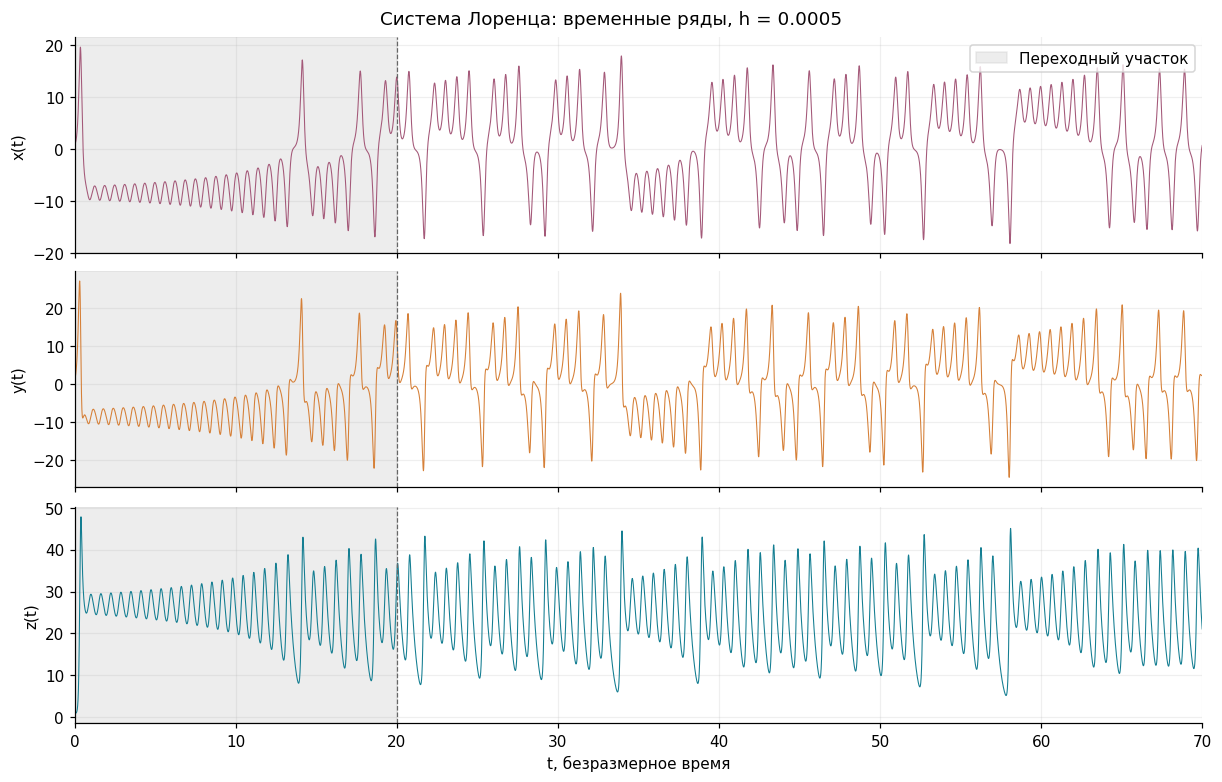

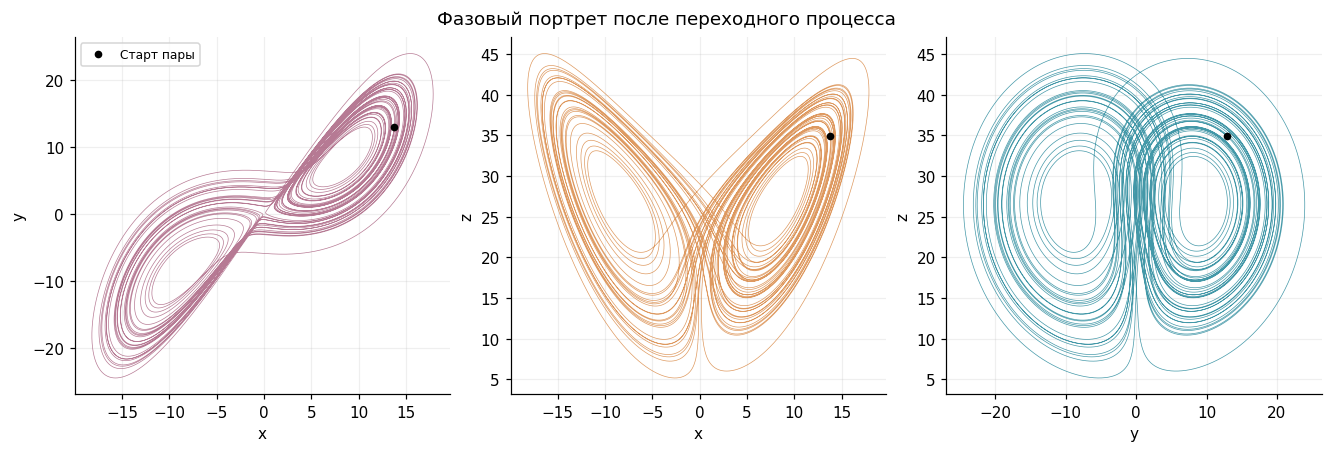

In [19]:
fine_h = steps[-1]
fine = runs[fine_h]
full_t = np.concatenate([transient_t, t_skip+fine["s"][1:]])
full_q = np.vstack([transient_q, fine["base"][1:]])

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
for i, ax in enumerate(axes):
    ax.plot(full_t, full_q[:, i], color=colors[i], lw=0.7)
    ax.axvspan(0, t_skip, color="#bbbbbb", alpha=0.25, label="Переходный участок")
    ax.axvline(t_skip, color="#666666", linestyle="--", lw=0.8)
    ax.set_ylabel(["x(t)", "y(t)", "z(t)"][i])
    ax.grid(alpha=0.2)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("t, безразмерное время")
axes[-1].set_xlim(0, t_skip+duration)
fig.suptitle("Система Лоренца: временные ряды, h = 0.0005")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, (i, j), color in zip(axes, [(0, 1), (0, 2), (1, 2)], colors):
    ax.plot(fine["base"][:, i], fine["base"][:, j], color=color, lw=0.45, alpha=0.8)
    ax.plot(start[i], start[j], "o", color="black", ms=4, label="Старт пары")
    ax.set(xlabel=["x", "y", "z"][i], ylabel=["x", "y", "z"][j])
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=8)
fig.suptitle("Фазовый портрет после переходного процесса")
plt.show()

### 4. Заданное возмущение и влияние точности расчёта

Расстояние между близкими траекториями, вычисленными с одним шагом:
$$d_h(s)=\|q^{(2)}_h(s)-q^{(1)}_h(s)\|_2.$$

Для сравнения настроек интегратора берём решения **из одинакового невозмущённого начального состояния**:
$$e_{h,h/2}(s)=\|q^{(1)}_h(s)-q^{(1)}_{h/2}(s)\|_2.$$
Величина $e$ показывает чувствительность вычисленного решения к шагу, но не является точной ошибкой относительно неизвестной аналитической траектории.

Сетки вложены. Сравниваем совпадающие моменты $s$ через срез массива; интерполяция не требуется. Нулевые расстояния, в частности $e(0)=0$, на логарифмической оси не отображаются.

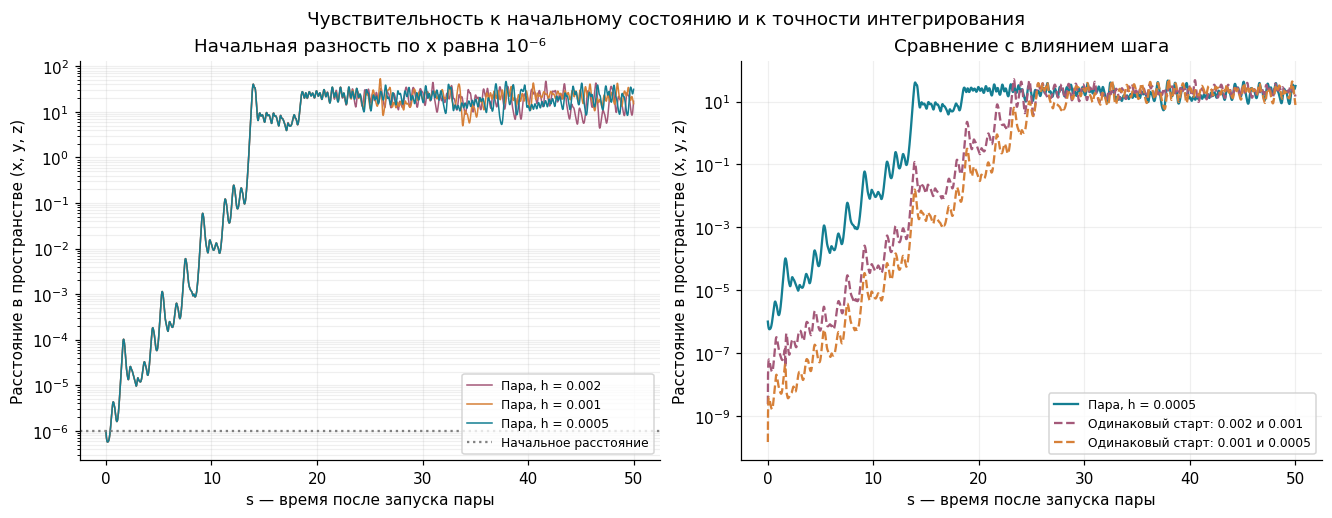

In [20]:
coarse_h, middle_h, fine_h = steps
common_s = runs[coarse_h]["s"]
aligned = {}
for h in steps:
    stride = int(round(coarse_h/h))
    aligned[h] = {key: runs[h][key][::stride]
                  for key in ["base", "perturbed", "distance"]}

numerical_coarse = np.linalg.norm(aligned[coarse_h]["base"]-aligned[middle_h]["base"], axis=1)
numerical_fine = np.linalg.norm(aligned[middle_h]["base"]-aligned[fine_h]["base"], axis=1)
d_fine = aligned[fine_h]["distance"]
d_middle = aligned[middle_h]["distance"]


def positive(values):
    return np.where(values > 0, values, np.nan)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
for h, color in zip(steps, colors):
    axes[0].semilogy(common_s, positive(aligned[h]["distance"]), color=color,
                     lw=1.0, label=f"Пара, h = {h:g}")
axes[0].axhline(delta0, color="gray", ls=":", label="Начальное расстояние")
axes[0].set_title("Начальная разность по x равна 10⁻⁶")
axes[1].semilogy(common_s, positive(d_fine), color=colors[-1], label="Пара, h = 0.0005")
axes[1].semilogy(common_s, positive(numerical_coarse), color=colors[0],
                 ls="--", label="Одинаковый старт: 0.002 и 0.001")
axes[1].semilogy(common_s, positive(numerical_fine), color=colors[1],
                 ls="--", label="Одинаковый старт: 0.001 и 0.0005")
axes[1].set_title("Сравнение с влиянием шага")
for ax in axes:
    ax.set(xlabel="s — время после запуска пары", ylabel="Расстояние в пространстве (x, y, z)")
    ax.grid(which="both", alpha=0.2)
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Чувствительность к начальному состоянию и к точности интегрирования")
plt.show()

### 5. Участок приблизительно экспоненциального роста

При малом расстоянии разность состояний приближённо удовлетворяет линейному уравнению
$$\dot{\delta q}\approx J(q(s))\,\delta q,$$
где $J$ — матрица производных правой части. Направления растяжения и сжатия меняются вдоль траектории. Поэтому расстояние может локально уменьшаться, хотя в среднем возмущение растёт.

Если на участке $d(s)\approx C\exp(as)$, то $\ln d(s)\approx\ln C+as$. На графике с логарифмической вертикальной осью такой средний рост похож на прямую линию.

Выделим участок **$2\le s\le12$**: начальная перестройка направления возмущения уже прошла, а расстояние ещё мало по сравнению с размером аттрактора. Оценим наклон линейной аппроксимации $\ln d(s)$ на этом одном и том же участке для всех трёх шагов.

Дополнительно оценим согласованность двух мелких сеток. Введём практический критерий:
$$e_{0.001,\,0.0005}(s)<0.1d_{0.0005}(s),\qquad
|d_{0.001}(s)-d_{0.0005}(s)|<0.1d_{0.0005}(s).$$
Число 10% выбрано для наглядности; это не строгая гарантия точности. Первое нарушение критерия означает, что детали наблюдаемого расхождения уже заметно зависят от шага. Если кривые позже случайно сблизятся, это не восстанавливает надёжность всего предшествующего расчёта.

Участок аппроксимации: 2 ≤ s ≤ 12
       h     Наклон ln d
  0.0020        0.923726
  0.0010        0.923726
  0.0005        0.923726
max e(0.001, 0.0005)/d на участке: 2.375e-03
max |d(0.001)-d(0.0005)|/d на участке: 8.791e-06
Первое нарушение критерия согласованности: s ≈ 23.154
Первое достижение d = 1: s ≈ 13.522
Первое достижение d = 10: s ≈ 13.756


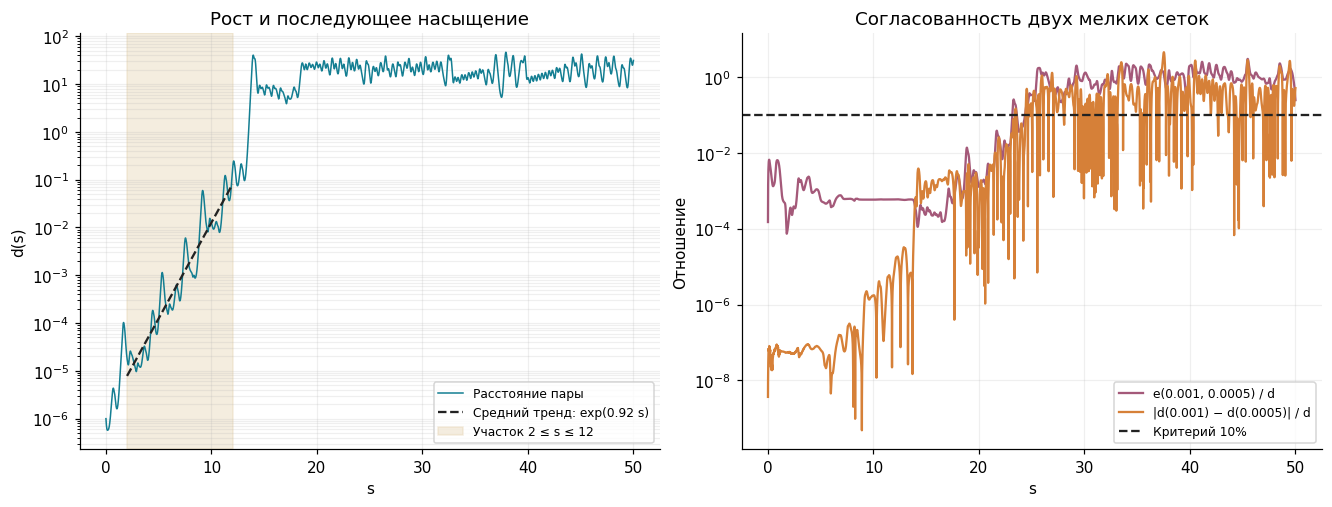

In [21]:
def first_crossing(times, values, threshold):
    hits = np.flatnonzero(values >= threshold)
    return float(times[hits[0]]) if len(hits) else np.nan


fine_grid_ratio = numerical_fine/d_fine
distance_ratio = np.abs(d_middle-d_fine)/d_fine
not_agreed = (fine_grid_ratio >= 0.1) | (distance_ratio >= 0.1)
bad_indices = np.flatnonzero(not_agreed)
agreement_end = common_s[bad_indices[0]] if len(bad_indices) else duration
fit_start, fit_end = 2.0, 12.0
fit_mask = (common_s >= fit_start) & (common_s <= fit_end)

print(f"Участок аппроксимации: {fit_start:g} ≤ s ≤ {fit_end:g}")
print(f"{'h':>8} {'Наклон ln d':>15}")
for h in steps:
    slope, _ = np.polyfit(common_s[fit_mask], np.log(aligned[h]["distance"][fit_mask]), 1)
    print(f"{h:8.4f} {slope:15.6f}")
rate, intercept = np.polyfit(common_s[fit_mask], np.log(d_fine[fit_mask]), 1)
fit_distance = np.exp(intercept+rate*common_s[fit_mask])

print(f"max e(0.001, 0.0005)/d на участке: {fine_grid_ratio[fit_mask].max():.3e}")
print(f"max |d(0.001)-d(0.0005)|/d на участке: {distance_ratio[fit_mask].max():.3e}")
if len(bad_indices):
    print(f"Первое нарушение критерия согласованности: s ≈ {agreement_end:.3f}")
else:
    print("Критерий согласованности выполнен на всём интервале.")
for threshold in [1.0, 10.0]:
    print(f"Первое достижение d = {threshold:g}: s ≈ {first_crossing(common_s, d_fine, threshold):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].semilogy(common_s, d_fine, color=colors[-1], lw=1, label="Расстояние пары")
axes[0].semilogy(common_s[fit_mask], fit_distance, "--", color="#222222",
                 label=f"Средний тренд: exp({rate:.2f} s)")
axes[0].axvspan(fit_start, fit_end, color="#e5d3b1", alpha=0.4, label="Участок 2 ≤ s ≤ 12")
axes[0].set(xlabel="s", ylabel="d(s)", title="Рост и последующее насыщение")
axes[0].legend(fontsize=8, loc="lower right")
axes[1].semilogy(common_s, positive(fine_grid_ratio), label="e(0.001, 0.0005) / d", color=colors[0])
axes[1].semilogy(common_s, positive(distance_ratio), label="|d(0.001) − d(0.0005)| / d", color=colors[1])
axes[1].axhline(0.1, color="#222222", ls="--", label="Критерий 10%")
axes[1].set(xlabel="s", ylabel="Отношение", title="Согласованность двух мелких сеток")
axes[1].legend(fontsize=8, loc="lower right")
for ax in axes:
    ax.grid(which="both", alpha=0.2)
plt.show()

Полученный наклон около $0.92$ характеризует выбранный конечный участок одной пары траекторий. Это не вычисление старшего показателя Ляпунова методом перенормировок. Изменение стартовой точки или интервала аппроксимации изменит оценку.

### 6. Почему рост прекращается

Экспоненциальное приближение относится к малому возмущению. Когда расстояние становится сравнимым с размером аттрактора, линейное приближение теряет смысл. Обе траектории продолжают двигаться в ограниченной области пространства состояний. Поэтому расстояние между ними не может неограниченно увеличиваться: оно колеблется на масштабе аттрактора. Насыщение не означает, что расстояние становится постоянным.

Для иллюстрации выведем диапазоны координат на расчёте с самым маленьким шагом и диапазон расстояний в конце опыта. На поздних временах конкретные положения уже зависят от шага, поэтому эти значения показывают лишь характерный масштаб.

In [22]:
states = fine["base"]
print("Диапазоны координат после переходного процесса:")
for i, name in enumerate(["x", "y", "z"]):
    print(f"{name}: [{states[:, i].min():.2f}, {states[:, i].max():.2f}]")
tail = fine["distance"][fine["s"] >= 40]
print(f"Расстояние пары при 40 ≤ s ≤ 50: от {tail.min():.2f} до {tail.max():.2f}")
print(f"Медиана расстояния на этом участке: {np.median(tail):.2f}")
print(f"При s = 0: {fine['distance'][0]:.3e}")

Диапазоны координат после переходного процесса:
x: [-18.18, 17.88]
y: [-24.53, 23.96]
z: [5.19, 45.07]
Расстояние пары при 40 ≤ s ≤ 50: от 8.38 до 42.61
Медиана расстояния на этом участке: 17.61
При s = 0: 1.000e-06


### Выводы

1. Временные ряды показывают нерегулярные колебания, а три фазовые проекции — ограниченную траекторию с двумя характерными областями вращения.
2. На участке $2\le s\le12$ рост начального различия $10^{-6}$ похож на экспоненциальный **в среднем**. Линейная аппроксимация $\ln d$ даёт наклон около $0.92$, воспроизводящийся при уменьшении шага. Поверх тренда наблюдаются колебания и локальные сближения.
3. На этом участке различие двух мелких сеток существенно меньше расстояния заданной пары. Примерно после $s=23$ выбранный критерий согласованности нарушается: детали расхождения уже заметно зависят от точности интегрирования. Это результат данного опыта, а не универсальная граница предсказуемости.
4. Уже около $s=14$ расстояние достигает порядка десяти. Далее рост ограничен размером аттрактора: расстояние колеблется, оставаясь конечным.

При точной детерминированной динамике одинаковое состояние даёт одинаковое решение. Расхождение двух численных решений из одного состояния связано с различиями приближённого интегрирования, которые хаотическая динамика затем усиливает.